# SQLite - analytics project with Chinook Database


## Imports and Installs

In [1]:
import sqlite3 as db
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Install sqlite3 in this env with magic statements
%%capture install_output
%%bash
apt-get update
apt-get install -y sqlite3
pip install sqlite-web

In [3]:
# Get the chinook database zip file with curl and unzip it
%%bash
[ -f chinook.zip ] ||
  curl -s -O https://www.sqlitetutorial.net/wp-content/uploads/2018/03/chinook.zip
unzip -l chinook.zip

Archive:  chinook.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
   884736  2015-11-29 10:53   chinook.db
---------                     -------
   884736                     1 file


In [4]:
!rm -f chinook.db

In [5]:
# Unzip the chinook zip file
!unzip -u chinook.zip

Archive:  chinook.zip
  inflating: chinook.db              


In [6]:
# get a list of all the files
!ls -la

total 1180
drwxr-xr-x 1 root root   4096 Oct 22 15:41 .
drwxr-xr-x 1 root root   4096 Oct 22 15:38 ..
-rw-r--r-- 1 root root 884736 Nov 29  2015 chinook.db
-rw-r--r-- 1 root root 305596 Oct 22 15:41 chinook.zip
drwxr-xr-x 4 root root   4096 Oct 17 23:09 .config
drwxr-xr-x 1 root root   4096 Oct 17 23:09 sample_data


## Basic Queries


#### SELECT, WHERE, NOT LIKE


In [7]:
# create a sqlite query that gets the names of the tables in the database
# sqlite_master is an internal, read_only system table in SQLite that stores the db
# schema, including tables, indexes, views, and triggers. It is created automatically
# for every db to map its structure. AKA sqlite_schema
# used for getting metadatea

# QUESTION: What are the names of the tables in the database
query = '''
  SELECT
    name
  FROM
    sqlite_master
  WHERE
    type='table' AND
    name NOT LIKE "sqlite_%"
;
'''

# create connection with context manager and query db, this will close the connections
# automatically

# get a list of the tables in the database with context managed query
with db.connect("chinook.db") as db_con:
  tables = pd.read_sql_query(query , db_con)

tables

,name
0,albums
1,artists
2,customers
3,employees
4,genres
5,invoices
6,invoice_items
7,media_types
8,playlists
9,playlist_track


In [8]:
# there are 11 tables in the database
tables.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   name    11 non-null     object
dtypes: object(1)
memory usage: 220.0+ bytes


In [9]:
tables.size

11

## Open an unmanaged connection

In [10]:
# make a connection that stays open
db_con = db.connect("chinook.db")

In [11]:
# make a function for the query and the connection
def make_query(query, connection):
  query_name = pd.read_sql_query(query, connection)
  return query_name

#### SELECT, FROM, WHERE, type =

In [12]:
# get the names of all the indexes
query = '''
  SELECT
    name
  FROM
    sqlite_master
  WHERE
    type='index';
'''

indices = make_query(query, db_con)

indices

,name
0,sqlite_autoindex_playlist_track_1
1,IFK_AlbumArtistId
2,IFK_CustomerSupportRepId
3,IFK_EmployeeReportsTo
4,IFK_InvoiceCustomerId
5,IFK_InvoiceLineInvoiceId
6,IFK_InvoiceLineTrackId
7,IFK_PlaylistTrackTrackId
8,IFK_TrackAlbumId
9,IFK_TrackGenreId


#### SELECT (with * and with column names)

In [13]:
# view the genres table
query = '''
  SELECT *
  FROM genres
;
'''

genres = make_query(query, db_con)

genres

,GenreId,Name
0,1,Rock
1,2,Jazz
2,3,Metal
3,4,Alternative & Punk
4,5,Rock And Roll
5,6,Blues
6,7,Latin
7,8,Reggae
8,9,Pop
9,10,Soundtrack


#### SELECT (with * and with column names), WHERE, LIKE, wildcard


In [14]:
# there are similar genres like "Rock" and "Rock And Roll"
query = '''
  SELECT *
  FROM genres
  WHERE name like "Rock%"
'''

# There are 2 similar "Rock" genres
rock_genres = make_query(query, db_con)

rock_genres

,GenreId,Name
0,1,Rock
1,5,Rock And Roll


In [40]:
genres.size
genres.shape

(25, 2)

#### SELECT, WHERE, AND, COLLATE NOCASE


In [17]:
# find customers from Sao Paulo, Brazil, ignore case
query = '''
  SELECT FirstName,
         LastName,
         Country,
         City
  FROM customers
  WHERE Country = "Brazil" COLLATE NOCASE
  AND City = "Sao Paolo" COLLATE NOCASE
;
'''

sao_paolo_customers = make_query(query, db_con)
sao_paolo_customers

,FirstName,LastName,Country,City


#### OR, WHERE, LIKE (with % or _ wildcard)


In [18]:
# there are two similar rock/rock and roll genres and two similar science fiction/sci fi & fantasy genres
query = '''
  SELECT *
  FROM genres
  WHERE name like "Rock%" OR name like "Sci%"
;'''

rock_and_sci = make_query(query, db_con)

rock_and_sci

,GenreId,Name
0,1,Rock
1,5,Rock And Roll
2,18,Science Fiction
3,20,Sci Fi & Fantasy


## Sorting and Grouping

#### CASE, WHEN, COUNT(), JOIN, GROUP BY, ORDER BY

In [19]:
# create a category by combining the rock and rock and roll genres. Count the number of tracks in each genre.

query = '''
  SELECT
    CASE
        WHEN g.Name IN ('Rock', 'Rock And Roll')
            THEN 'Rock' -- Combine the rock and rock and roll categories
        ELSE g.Name -- all other genres remain the same
    END AS GenreGroup, -- create a new output column name "GenreGroup"

    COUNT(*) AS NumberOfTracks -- count the number of tracks in the each genre group

  FROM tracks t
  JOIN genres g
      ON t.GenreId = g.GenreId -- join tracks and genres on GenreID

  GROUP BY GenreGroup
  ORDER BY NumberOfTracks DESC -- order from highest to lowest
;'''

rock_combined = pd.read_sql_query(query, db_con)

rock_combined

,GenreGroup,NumberOfTracks
0,Rock,1309
1,Latin,579
2,Metal,374
3,Alternative & Punk,332
4,Jazz,130
5,TV Shows,93
6,Blues,81
7,Classical,74
8,Drama,64
9,R&B/Soul,61


In [20]:
# view all of the invoices
query = '''
  SELECT *
  FROM invoices
;
'''

# function to make querying easier
invoices = make_query(query, db_con)
invoices

,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total
0,1,2,2009-01-01 00:00:00,Theodor-Heuss-Straße 34,Stuttgart,None,Germany,70174,1.98
1,2,4,2009-01-02 00:00:00,Ullevålsveien 14,Oslo,None,Norway,0171,3.96
2,3,8,2009-01-03 00:00:00,Grétrystraat 63,Brussels,None,Belgium,1000,5.94
3,4,14,2009-01-06 00:00:00,8210 111 ST NW,Edmonton,AB,Canada,T6G 2C7,8.91
4,5,23,2009-01-11 00:00:00,69 Salem Street,Boston,MA,USA,2113,13.86
...,...,...,...,...,...,...,...,...,...
407,408,25,2013-12-05 00:00:00,319 N. Frances Street,Madison,WI,USA,53703,3.96
408,409,29,2013-12-06 00:00:00,796 Dundas Street West,Toronto,ON,Canada,M6J 1V1,5.94
409,410,35,2013-12-09 00:00:00,"Rua dos Campeões Europeus de Viena, 4350",Porto,None,Portugal,None,8.91
410,411,44,2013-12-14 00:00:00,Porthaninkatu 9,Helsinki,None,Finland,00530,13.86


In [21]:
# Select the first 10 entries from joining the artists and albums tables
%%script sqlite3 --column --header chinook.db
select *
from artists
join albums
on artists.ArtistID = albums.ArtistID
limit 10


ArtistId  Name                  AlbumId  Title                                  ArtistId
--------  --------------------  -------  -------------------------------------  --------
1         AC/DC                 1        For Those About To Rock We Salute You  1       
2         Accept                2        Balls to the Wall                      2       
2         Accept                3        Restless and Wild                      2       
1         AC/DC                 4        Let There Be Rock                      1       
3         Aerosmith             5        Big Ones                               3       
4         Alanis Morissette     6        Jagged Little Pill                     4       
5         Alice In Chains       7        Facelift                               5       
6         Antônio Carlos Jobim  8        Warner 25 Anos                         6       
7         Apocalyptica          9        Plays Metallica By Four Cellos         7       
8         Audioslave 

## What are the best selling genres?


In [22]:
query = '''
  SELECT g.Name AS Genre,
    COUNT(ii.InvoiceLineId) AS Purchases
  FROM invoice_items ii
  JOIN tracks t
      ON ii.TrackId = t.TrackId

  JOIN genres g
    ON t.GenreId = g.GenreId
  GROUP BY g.Name
  ORDER BY Purchases DESC
  LIMIT 5;
  '''
# the top five most purchased genres
top_five_genres = pd.read_sql_query(query, db_con)
top_five_genres

,Genre,Purchases
0,Rock,835
1,Latin,386
2,Metal,264
3,Alternative & Punk,244
4,Jazz,80



name
0	albums
1	artists
2	customers
3	employees
4	genres
5	invoices
6	invoice_items
7	media_types
8	playlists
9	playlist_track
10	tracks


## Who is the best selling artist?


In [23]:
query = '''
  SELECT ar.Name AS Artist,
    SUM(ii.UnitPrice * ii.Quantity) AS Revenue
  FROM invoice_items ii

  JOIN tracks t
    ON ii.TrackId = t.TrackId

  JOIN albums al
    ON t.AlbumId = al.AlbumId

  JOIN artists ar
    ON al.ArtistId = ar.ArtistId

  GROUP BY ar.Name
  ORDER BY Revenue DESC
  LIMIT 10;
  '''

best_selling_artist = pd.read_sql_query(query, db_con)
best_selling_artist

,Artist,Revenue
0,Iron Maiden,138.60
1,U2,105.93
2,Metallica,90.09
3,Led Zeppelin,86.13
4,Lost,81.59
5,The Office,49.75
6,Os Paralamas Do Sucesso,44.55
7,Deep Purple,43.56
8,Faith No More,41.58
9,Eric Clapton,39.60


## What is the best selling album?

In [24]:
query = '''
SELECT al.Title AS Album,
  ar.Name AS Artist,
  COUNT(ii.InvoiceLineId) AS TotalSales

FROM invoice_items ii
JOIN tracks t
  ON ii.TrackId = t.TrackId

JOIN albums al
  ON t.AlbumId = al.AlbumId

JOIN artists ar
  ON al.ArtistID = ar.ArtistID

GROUP BY al.Title
ORDER BY TotalSales DESC
LIMIT 1;
'''

best_selling_album = pd.read_sql_query(query, db_con)
best_selling_album

,Album,Artist,TotalSales
0,Minha Historia,Chico Buarque,27


## Aggregates


#### MIN


In [25]:
# What is the least purchased album?
query = '''
  SELECT al.Title AS Album,
  COUNT(ii.InvoiceLineId) AS TotalSales
  FROM invoice_items ii

  JOIN tracks t
  ON ii.TrackId = t.TrackId

  JOIN albums al
  ON t.AlbumId = al.AlbumId

  GROUP BY al.Title
  ORDER BY TotalSales ASC
  LIMIT 1;
'''

worst_album = pd.read_sql_query(query, db_con)
worst_album

,Album,TotalSales
0,"Adams, John: The Chairman Dances",1


#### SUM


In [26]:
# What is the total revenue from all the invoices?
query = '''
  SELECT SUM(Total) AS TotalRevenue
  FROM invoices;
'''
total_rev = pd.read_sql_query(query, db_con)
total_rev

,TotalRevenue
0,2328.6


#### AVG


In [27]:
# What is the average invoice total?
query = '''
  SELECT AVG(Total) AS AvgInvoice
  FROM invoices;
  '''

ave_invoice = pd.read_sql_query(query, db_con)
ave_invoice

,AvgInvoice
0,5.651942


What are the top genres by sales?

In [28]:
query = '''
  SELECT g.Name AS Genre,
    COUNT(ii.InvoiceLineId) AS Sales
  FROM invoice_items ii

  JOIN tracks t
    ON ii.TrackID = t.TrackId

  JOIN genres g
    ON t.GenreId = g.GenreId

  GROUP BY g.Name
  ORDER BY Sales DESC
  LIMIT 10
;
'''
top_genres = pd.read_sql_query(query, db_con)
top_genres

,Genre,Sales
0,Rock,835
1,Latin,386
2,Metal,264
3,Alternative & Punk,244
4,Jazz,80
5,Blues,61
6,TV Shows,47
7,R&B/Soul,41
8,Classical,41
9,Reggae,30


## Visualizations



### Bar plot of the top genres by sales.

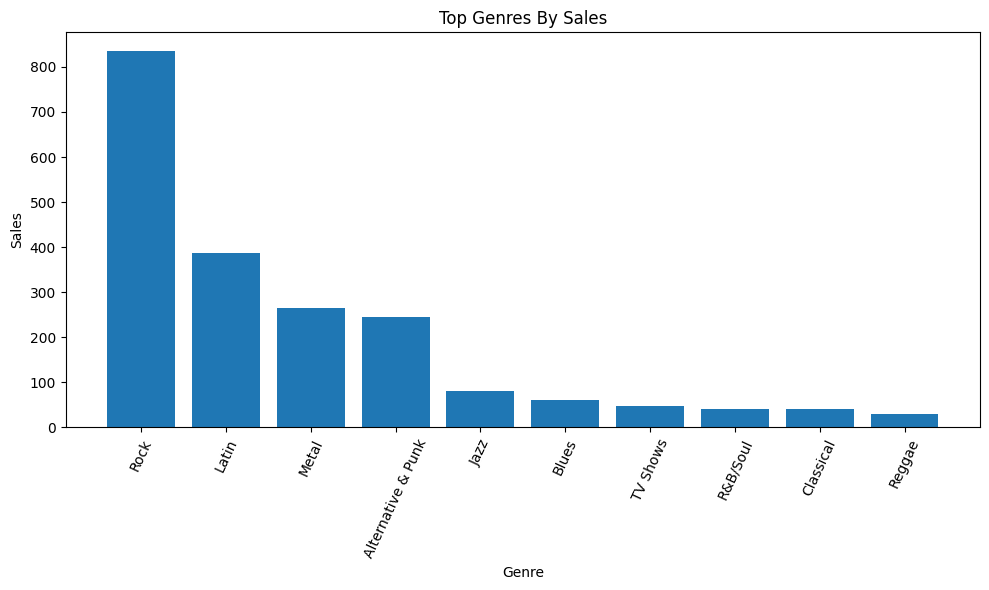

In [29]:
# plot genres by sales
plt.figure(figsize=(10,6))
plt.bar(top_genres["Genre"], top_genres["Sales"])
plt.xticks(rotation=65)
plt.xlabel('Genre')
plt.ylabel('Sales')
plt.title('Top Genres By Sales')

plt.tight_layout()
plt.show()

## Plot the revenue per country with CTE

In [30]:
query = '''
WITH country_revenue AS (
    SELECT
      BillingCountry,
      SUM(Total) AS Revenue
    FROM invoices
    GROUP BY BillingCountry
)
SELECT
  BillingCountry, Revenue
FROM country_revenue
ORDER BY Revenue DESC;

'''

rev_per_country = pd.read_sql_query(query, db_con)
rev_per_country

,BillingCountry,Revenue
0,USA,523.06
1,Canada,303.96
2,France,195.10
3,Brazil,190.10
4,Germany,156.48
5,United Kingdom,112.86
6,Czech Republic,90.24
7,Portugal,77.24
8,India,75.26
9,Chile,46.62


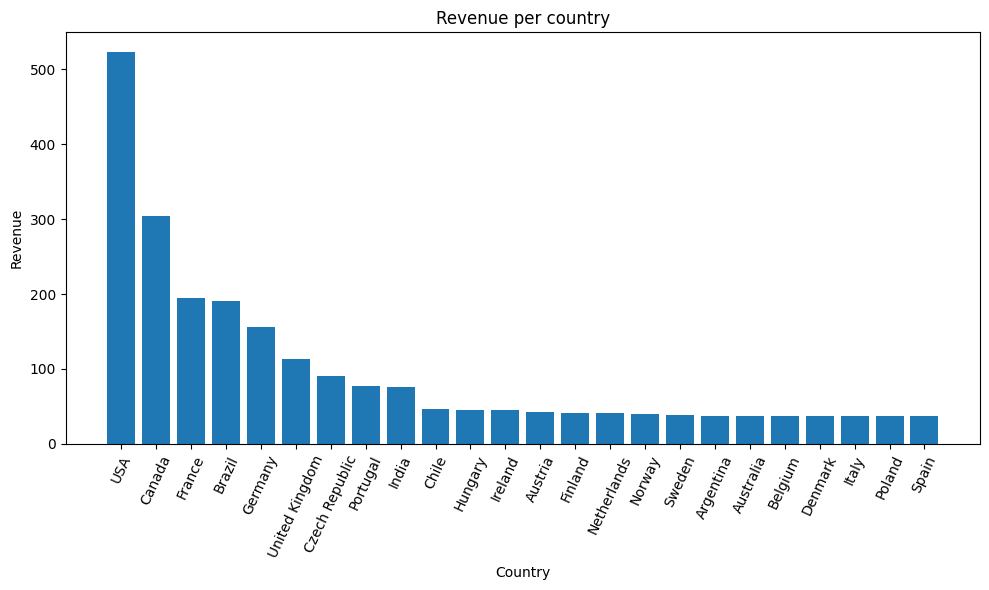

In [31]:
# plot the revenues for each country
plt.figure(figsize=(10,6))
plt.bar(rev_per_country["BillingCountry"], rev_per_country["Revenue"])
plt.xticks(rotation=65)
plt.xlabel('Country')
plt.ylabel('Revenue')
plt.title('Revenue per country')

plt.tight_layout()
plt.show()

### Sort the table by longest song

In [32]:
query = '''
WITH song_lengths AS (
  SELECT
    Name AS TrackName,
    Milliseconds / 60000.0 AS Minutes
  FROM
    tracks
)
SELECT
  TrackName,
  Minutes
FROM song_lengths
ORDER BY Minutes DESC;
'''
song_lengths = pd.read_sql_query(query, db_con)
song_lengths

,TrackName,Minutes
0,Occupation / Precipice,88.115883
1,Through a Looking Glass,84.813967
2,"Greetings from Earth, Pt. 1",49.338217
3,The Man With Nine Lives,49.283300
4,"Battlestar Galactica, Pt. 2",49.268017
...,...,...
3498,Commercial 1,0.132350
3499,Oprah,0.110583
3500,A Statistic,0.106217
3501,Now Sports,0.081400


In [33]:
song_lengths.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Minutes,3503.0,6.559987,8.916757,0.01785,3.454683,4.260567,5.36075,88.115883


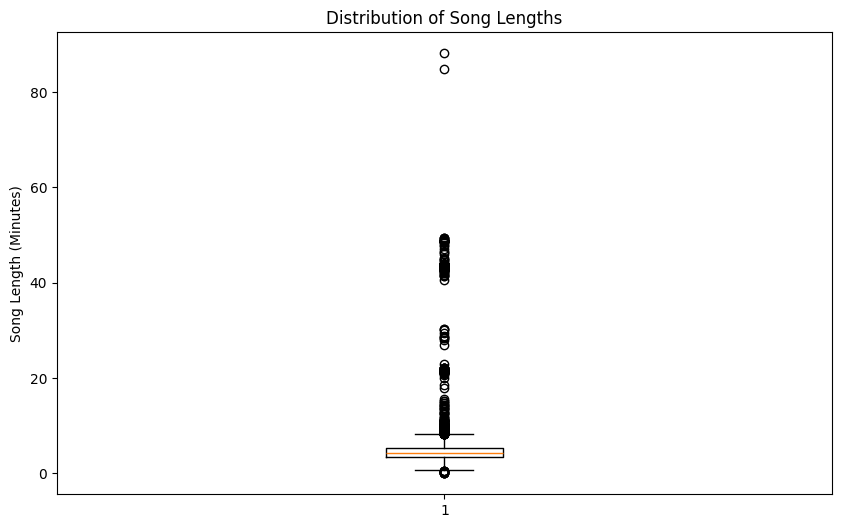

In [34]:
# Create box plot
plt.figure(figsize=(10,6))

plt.boxplot(song_lengths["Minutes"])

plt.ylabel("Song Length (Minutes)")
plt.title("Distribution of Song Lengths")

plt.show()

<function ylabel at 0x7c8752ce89a0>


Text(0.5, 0, 'Songs')

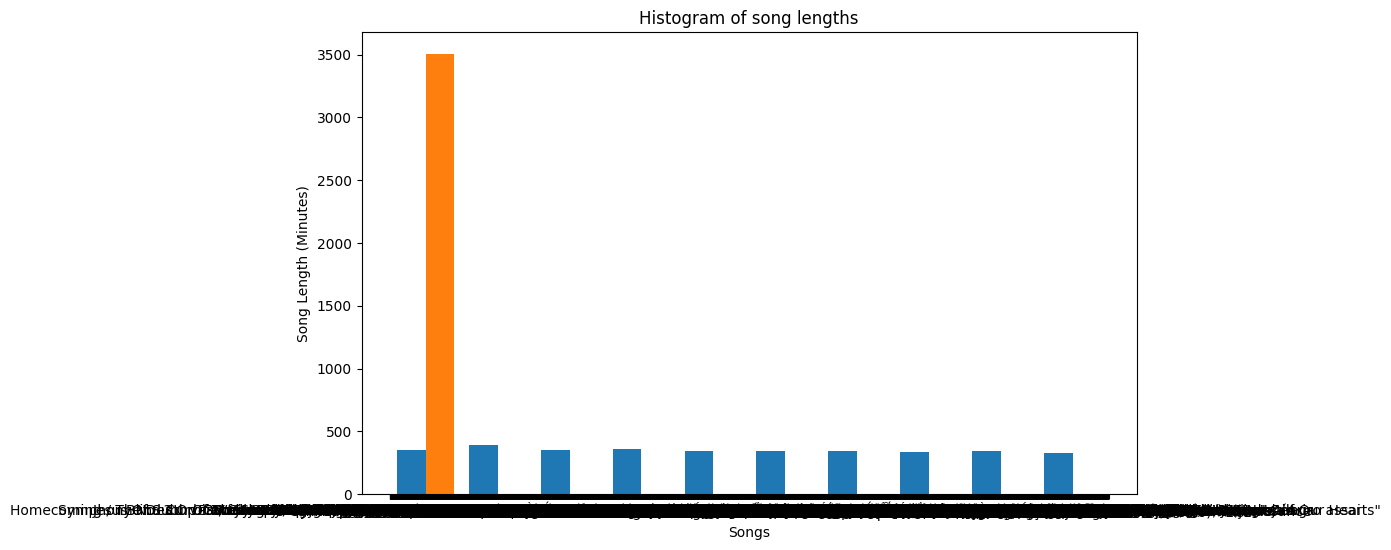

In [35]:
# plot a histogram of song lengths
plt.figure(figsize=(10,6))
plt.hist(song_lengths)

plt.title("Histogram of song lengths")
plt.ylabel('Song Length (Minutes)')
print(plt.ylabel)
plt.xlabel('Songs')


In [36]:
song_lengths['Minutes'].head()

,Minutes
0,88.115883
1,84.813967
2,49.338217
3,49.283300
4,49.268017


In [37]:
song_lengths.head()

,TrackName,Minutes
0,Occupation / Precipice,88.115883
1,Through a Looking Glass,84.813967
2,"Greetings from Earth, Pt. 1",49.338217
3,The Man With Nine Lives,49.283300
4,"Battlestar Galactica, Pt. 2",49.268017


#### There are a couple of songs that are over 80 minutes long and quite a few that are much longer than songs you might hear on the radio.

In [38]:
# get the songs that are less than ten minutes long
query = '''
WITH song_lengths AS (
  SELECT
    Name AS TrackName,
    Milliseconds / 60000.0 AS Minutes
  FROM
    tracks
)
SELECT
  TrackName,
  Minutes
FROM song_lengths
WHERE Minutes < 10;
'''
song_lengths_lt_10 = pd.read_sql_query(query, db_con)
song_lengths_lt_10

,TrackName,Minutes
0,For Those About To Rock (We Salute You),5.728650
1,Balls to the Wall,5.709367
2,Fast As a Shark,3.843650
3,Restless and Wild,4.200850
4,Princess of the Dawn,6.256967
...,...,...
3238,Pini Di Roma (Pinien Von Rom) \ I Pini Della V...,4.779017
3239,"String Quartet No. 12 in C Minor, D. 703 ""Quar...",2.320000
3240,"L'orfeo, Act 3, Sinfonia (Orchestra)",1.110650
3241,"Quintet for Horn, Violin, 2 Violas, and Cello ...",3.688850
